# Data Pipeline Incident Agent

**Executed offline notebook**. All sources are fictional and requests run the same `agent.py` code as the CLI and Streamlit app. The negative case deliberately injects a tool failure.

In [1]:
from pathlib import Path
import sys, json
from IPython.display import display, Image
BASE=Path.cwd()
sys.path.insert(0,str(BASE.parent))
from agent import run
CASES=json.loads((BASE/"data/eval_cases.json").read_text())
print("Dataset:",BASE.name,"| tasks:",len(CASES))

Dataset: 06-pipeline-incident-agent | tasks: 5


## Successful / approval-safe execution (actual local workflow)

In [2]:
case=next(c for c in CASES if c["id"]=='quota')
success=run(case["request"],BASE,case.get("fault"))
print(json.dumps({"status":success["status"],"answer":success["answer"],"evidence":success["evidence"],"trace":success["trace"]},indent=2,ensure_ascii=False))
assert success["status"] == case["expected_status"]

{
  "status": "needs_approval",
  "answer": "Likely cause: Storage quota exhausted. Recommendation: Escalate capacity investigation; do not purge data automatically. Remediation not executed.",
  "evidence": [
    {
      "incident": "INC-1",
      "log": "Warehouse load failed: STORAGE_QUOTA exceeded 100GB limit",
      "upstream": [
        "daily_orders"
      ]
    }
  ],
  "trace": [
    {
      "tool": "incidents",
      "ok": true,
      "elapsed_ms": 0.352,
      "output_preview": "[{'incident_id': 'INC-1', 'pipeline_id': 'warehouse_load', 'log': 'Warehouse load failed: STORAGE_QUOTA exceeded 100GB limit', 'time': '2026-04-01T08:00:00Z'}, {'incident_id': 'INC"
    },
    {
      "tool": "lineage",
      "ok": true,
      "elapsed_ms": 0.631,
      "output_preview": "[{'pipeline_id': 'daily_orders', 'depends_on': ['ingest_orders'], 'runbook': 'Check upstream ingestion, retry only after approval'}, {'pipeline_id': 'warehouse_load', 'depends_on':"
    },
    {
      "tool": "diagn

## Failure case with a real injected tool exception

In [3]:
case=next(c for c in CASES if c["id"]=='fault')
failure=run(case["request"],BASE,case["fault"])
print(json.dumps({"status":failure["status"],"answer":failure["answer"],"trace":failure["trace"]},indent=2,ensure_ascii=False))
assert failure["status"] == "error"
assert any(not x["ok"] for x in failure["trace"])

{
  "status": "error",
  "answer": "RuntimeError: Injected tool fault: lineage",
  "trace": [
    {
      "tool": "incidents",
      "ok": true,
      "elapsed_ms": 0.132,
      "output_preview": "[{'incident_id': 'INC-1', 'pipeline_id': 'warehouse_load', 'log': 'Warehouse load failed: STORAGE_QUOTA exceeded 100GB limit', 'time': '2026-04-01T08:00:00Z'}, {'incident_id': 'INC"
    },
    {
      "tool": "lineage",
      "ok": false,
      "elapsed_ms": 0.005,
      "error": "RuntimeError: Injected tool fault: lineage"
    }
  ]
}


## Archived fixture evaluation and generated evidence chart

Passed 5 of 5 fixture tasks
Tool failure rate 0.0833 | Mean latency (ms) 0.064 | Hosted model spend ($) 0.0


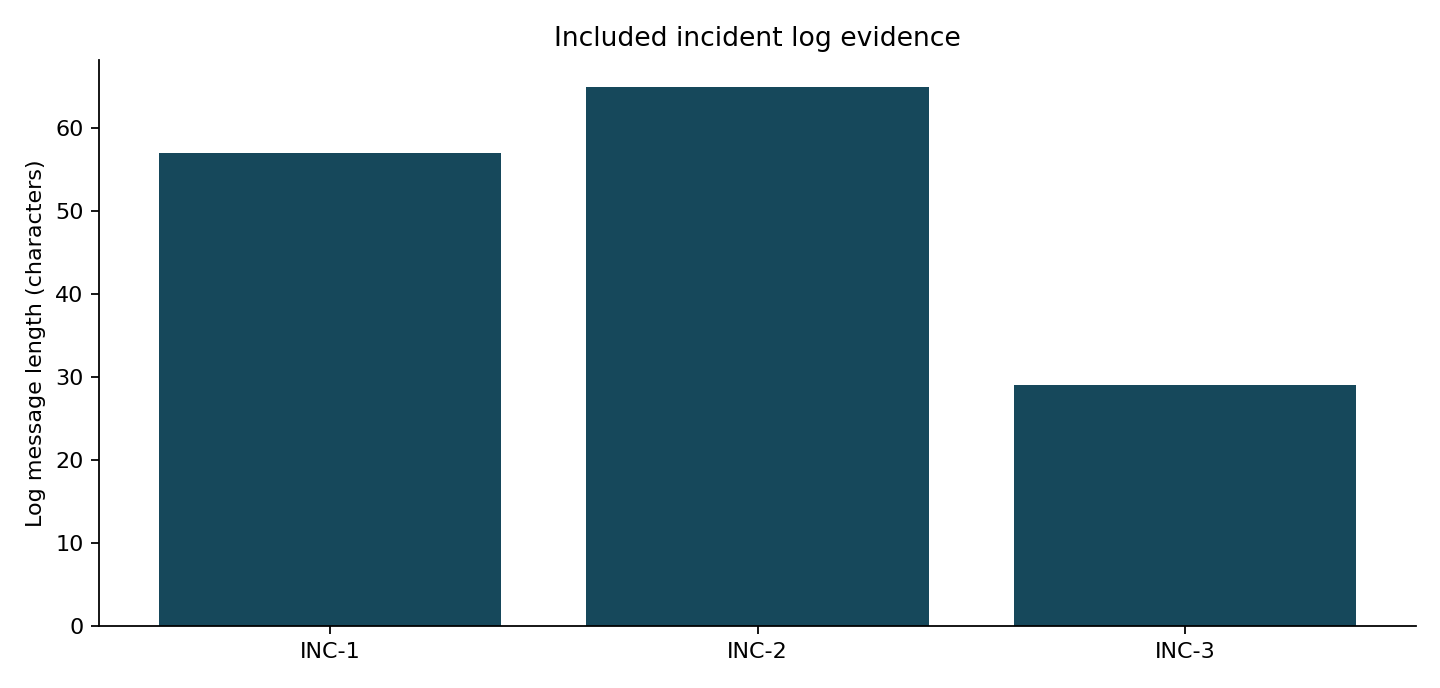

In [4]:
report=json.loads((BASE/"outputs/evaluation.json").read_text())
print("Passed",report["passed"],"of",report["cases"],"fixture tasks")
print("Tool failure rate",report["tool_failure_rate"],"| Mean latency (ms)",report["mean_latency_ms"],"| Hosted model spend ($)",report["total_model_api_cost_usd"])
display(Image(filename=str(BASE/"outputs/overview.png")))